# Imports and Reading data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
plt.style.use('ggplot')
pd.set_option('display.max_columns', 200)

In [2]:
df = pd.read_csv('OTO-ESC-10k.csv')

# Data understanding

In [3]:
df.shape

# Check the number of rows and columns.

(10000, 11)

In [4]:
df.columns

Index(['optimizer_gain', 'dither_amplitude', 'dither_frequency', 'r_ideal_0',
       'lambda_r_ideal', 'energy_ESC', 'energy_const', 'energy_max',
       'choose_ESC', 'converged', 'convergence_time'],
      dtype='str')

In [5]:
df.head(5)

,optimizer_gain,dither_amplitude,dither_frequency,r_ideal_0,lambda_r_ideal,energy_ESC,energy_const,energy_max,choose_ESC,converged,convergence_time
0,0.232771,0.650749,8.173705,0.487418,-0.001241,3292.653445,3268.154800,3306.25,1,1,6.91
1,0.000409,0.646502,0.036053,0.513860,0.000368,1475.605545,3285.337058,3306.25,0,1,0.00
2,0.000050,0.325289,9.889513,0.523588,-0.001374,3286.843520,3286.606728,3306.25,1,1,0.00
3,0.001125,0.434647,8.322432,0.457624,0.000228,3278.537946,3276.002851,3306.25,1,0,NaN
4,0.097121,0.273930,1.320547,0.498590,-0.001269,3281.224569,3276.821611,3306.25,1,1,11.71


In [6]:
df.dtypes

optimizer_gain      float64
dither_amplitude    float64
dither_frequency    float64
r_ideal_0           float64
lambda_r_ideal      float64
energy_ESC          float64
energy_const        float64
energy_max          float64
choose_ESC            int64
converged             int64
convergence_time    float64
dtype: object

# Data preparation

In [7]:
df.isna().sum()

# Check missing values and duplicate rows before analysis.

optimizer_gain         0
dither_amplitude       0
dither_frequency       0
r_ideal_0              0
lambda_r_ideal         0
energy_ESC             0
energy_const           0
energy_max             0
choose_ESC             0
converged              0
convergence_time    2516
dtype: int64

# Feature understanding

Text(0, 0.5, 'Counts')

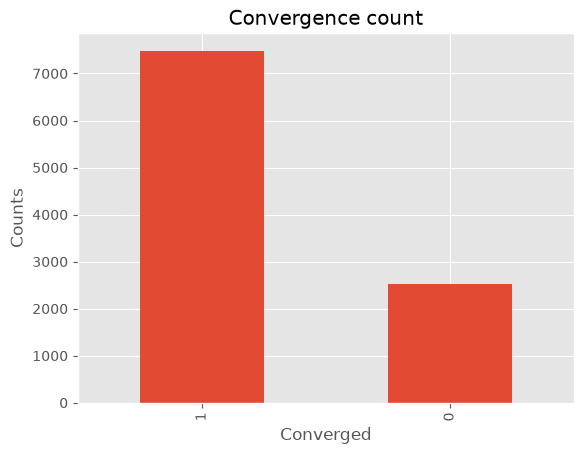

In [8]:
cv = df['converged'].value_counts().head(10).plot(kind = 'bar', title = 'Convergence count')

cv.set_xlabel('Converged')
cv.set_ylabel('Counts')

# More than 70% converged. I think this is a healthy spread as we care more about the converged combinations

Text(0, 0.5, 'Frequency')

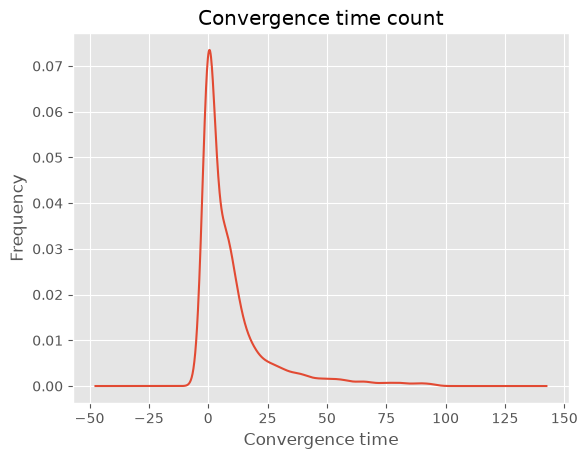

In [9]:
ct = df['convergence_time'].plot(kind = 'kde',
                title = 'Convergence time count')
ct.set_xlabel('Convergence time')
ct.set_ylabel('Frequency')

# A majority of combinations lead to convergence time < 12.5 seconds

In [10]:
sum(df['convergence_time'] < 5)

# 3928 combinations have convergence time < 5

3928

In [11]:
sum(df['convergence_time'] < 1)

# 3928 combinations have convergence time < 1. So mainly the fast converging combinations are by being already inside the r_ideal region at the start

3150

# Feature relationships

## Full dataset

### Convergence time

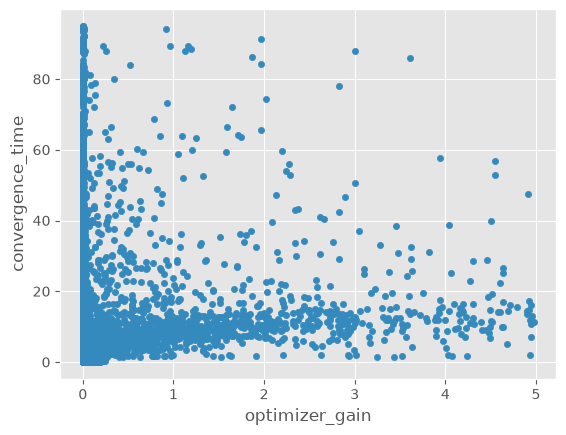

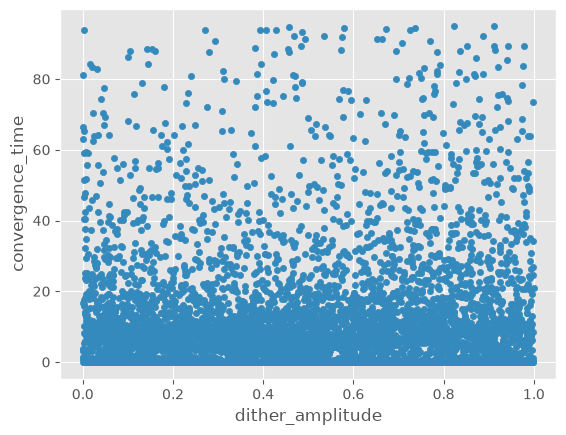

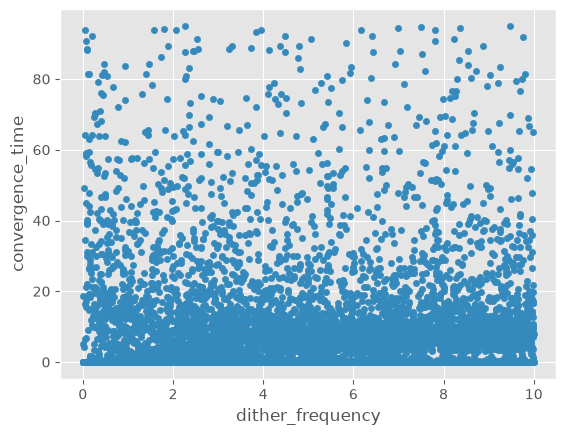

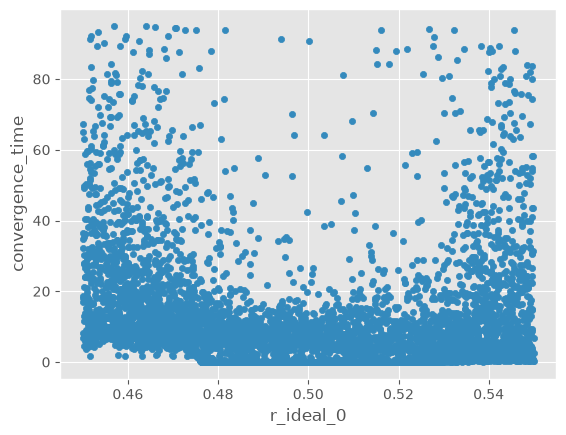

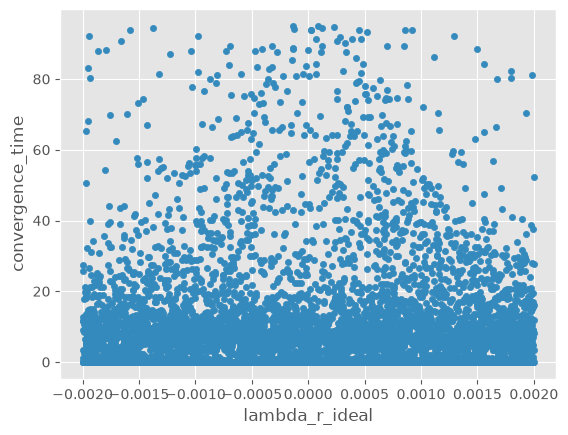

In [12]:
parameter_columns = ['optimizer_gain', 'dither_amplitude', 'dither_frequency', 'r_ideal_0', 'lambda_r_ideal']
for i in parameter_columns:
    df.plot(kind = 'scatter',
            x = i,
            y = 'convergence_time')
    plt.show()


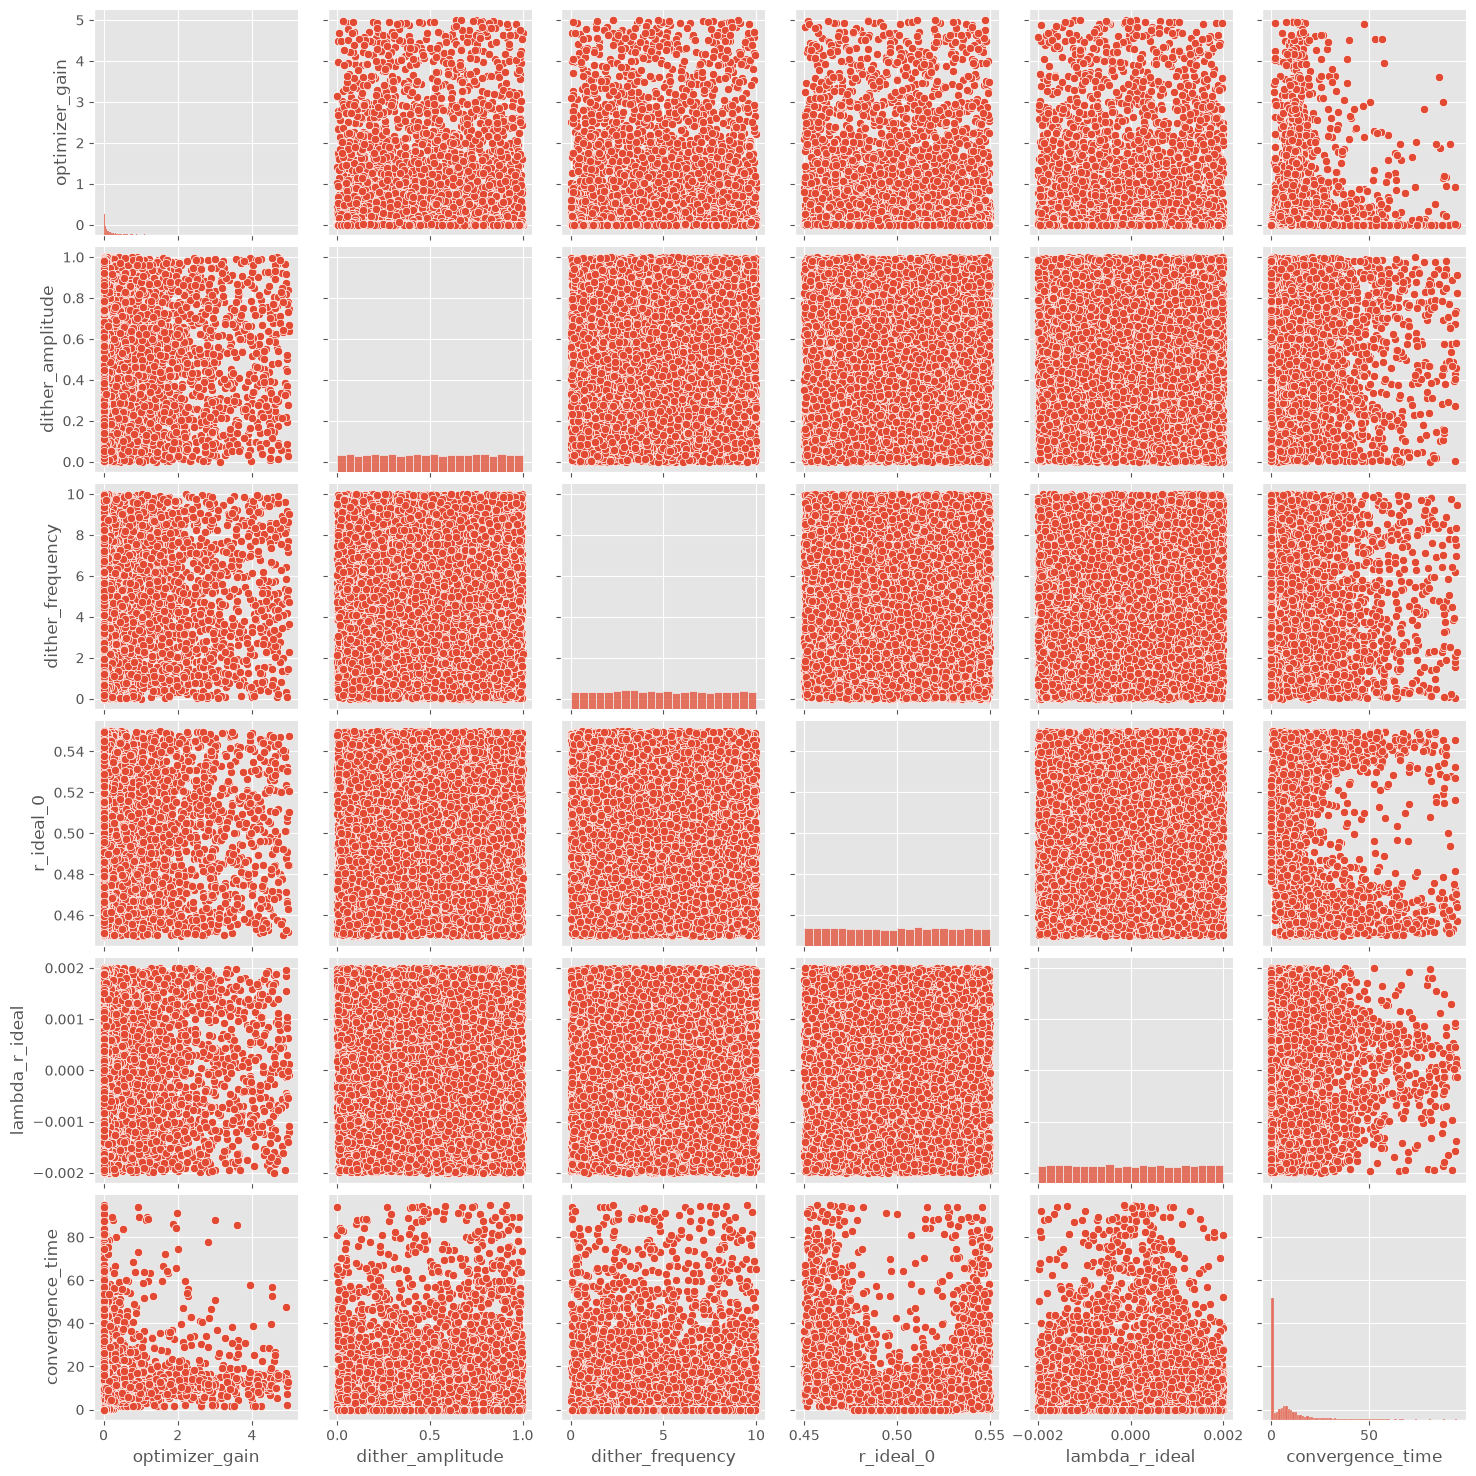

In [13]:
sns.pairplot(df,
             vars = parameter_columns + ['convergence_time'])
plt.show()


<Axes: >

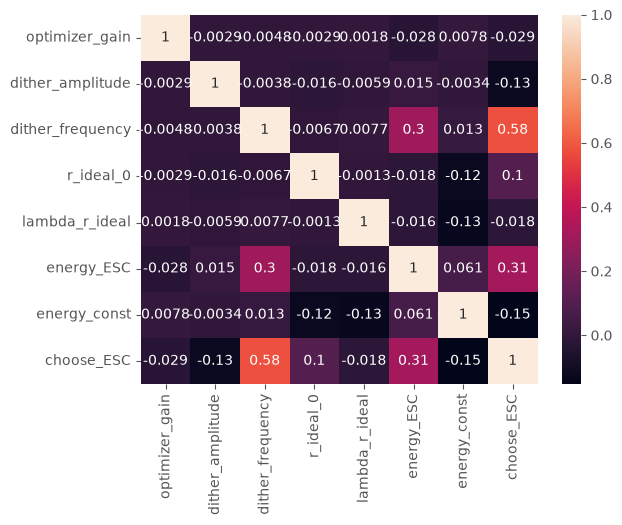

In [14]:
sns.heatmap(df.drop(columns = ['converged', 'convergence_time', 'energy_max']).corr(), annot = True)


### Energy generated

#### Compare methods and max energy

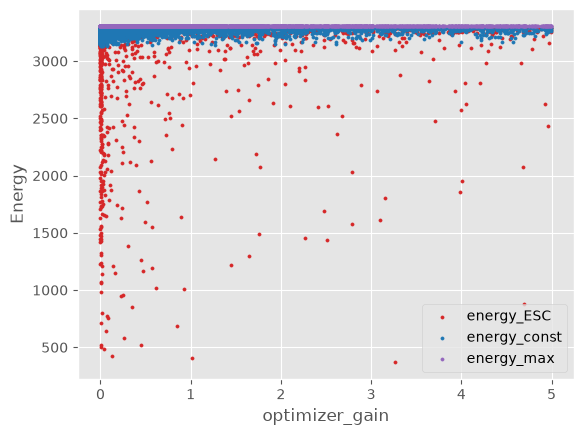

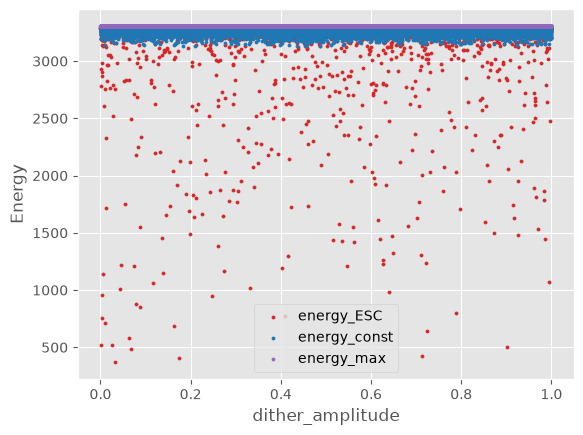

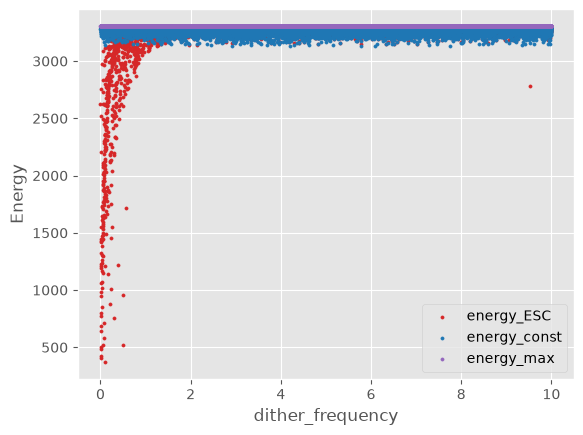

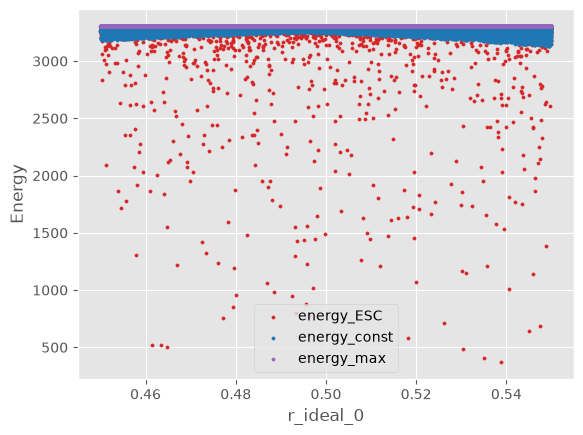

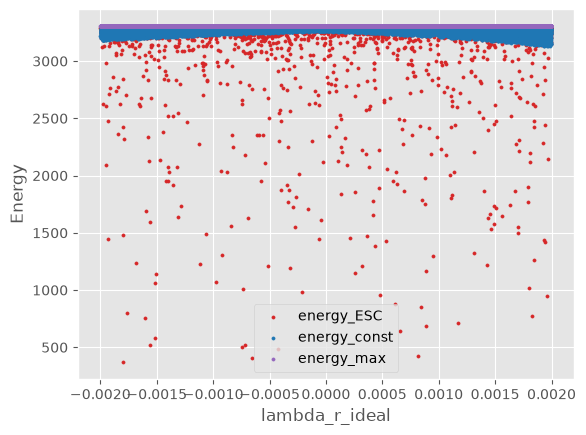

In [15]:
parameter_columns = ['optimizer_gain', 'dither_amplitude', 'dither_frequency', 'r_ideal_0', 'lambda_r_ideal']
energy_columns = ['energy_ESC', 'energy_const', 'energy_max']

for i in parameter_columns:
    ax = df.plot(kind = 'scatter', x = i, y = 'energy_ESC', color = 'tab:red', label = 'energy_ESC', s = 5)
    df.plot(kind = 'scatter', x = i, y = 'energy_const', color = 'tab:blue', label = 'energy_const', s = 5, ax = ax)
    df.plot(kind = 'scatter', x = i, y = 'energy_max', color = 'tab:purple', label = 'energy_max', s = 5, ax = ax)
    ax.set_ylabel('Energy')
    plt.show()


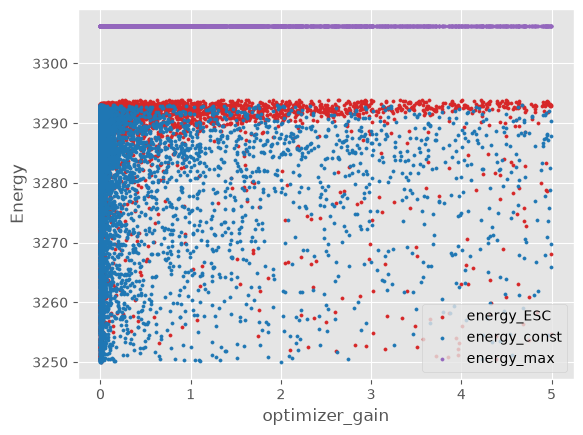

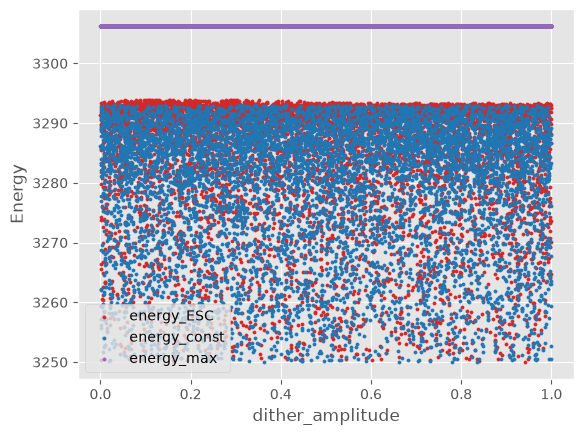

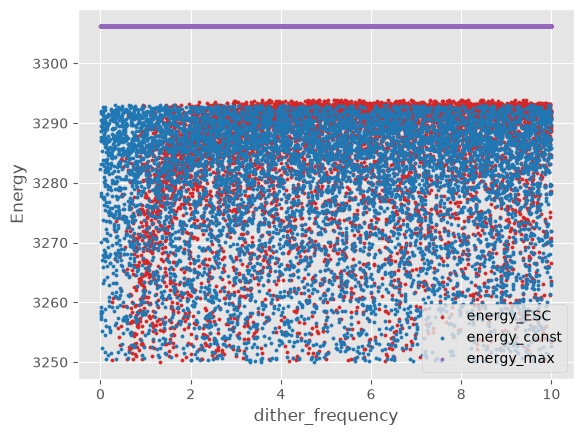

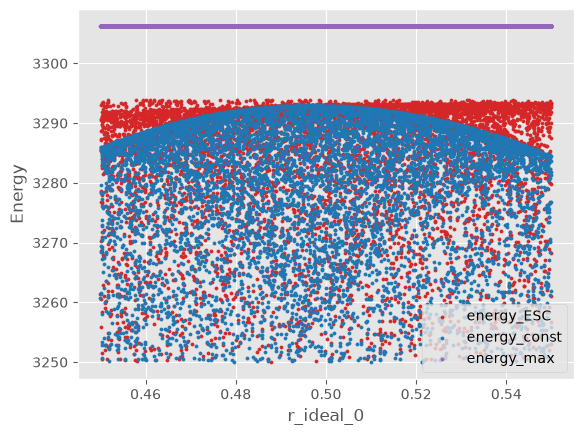

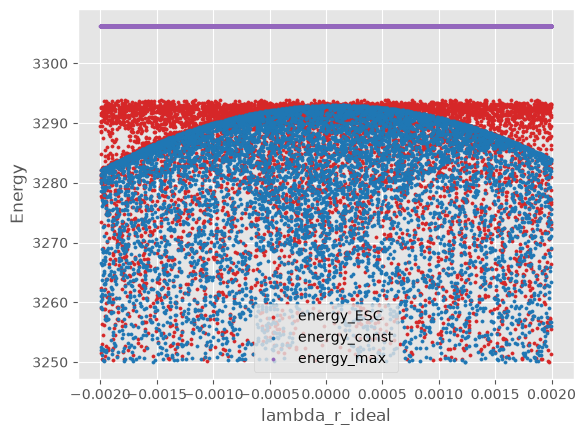

In [16]:

for i in parameter_columns:
    ax = df[df['energy_ESC'] > 3250].plot(kind = 'scatter', x = i, y = 'energy_ESC', color = 'tab:red', label = 'energy_ESC', s = 5)
    df[df['energy_const'] > 3250].plot(kind = 'scatter', x = i, y = 'energy_const', color = 'tab:blue', label = 'energy_const', s = 5, ax = ax)
    df[df['energy_max'] > 3250].plot(kind = 'scatter', x = i, y = 'energy_max', color = 'tab:purple', label = 'energy_max', s = 5, ax = ax)
    ax.set_ylabel('Energy')
    plt.show()

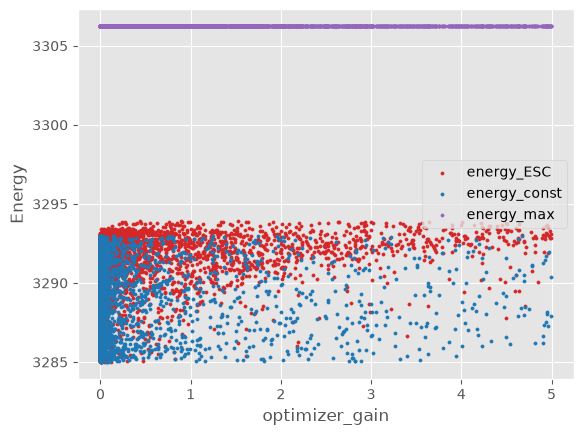

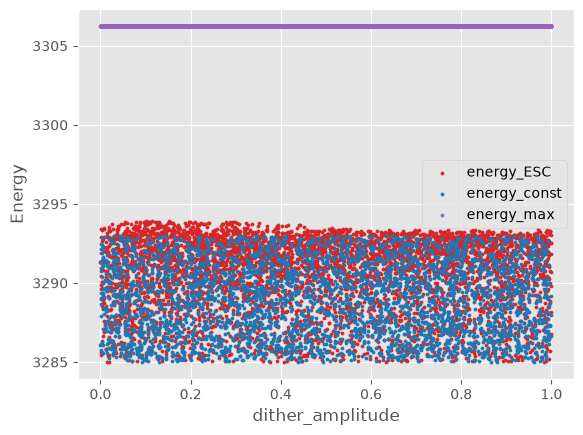

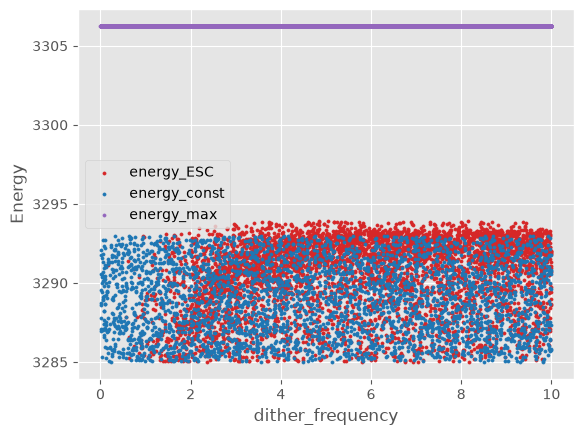

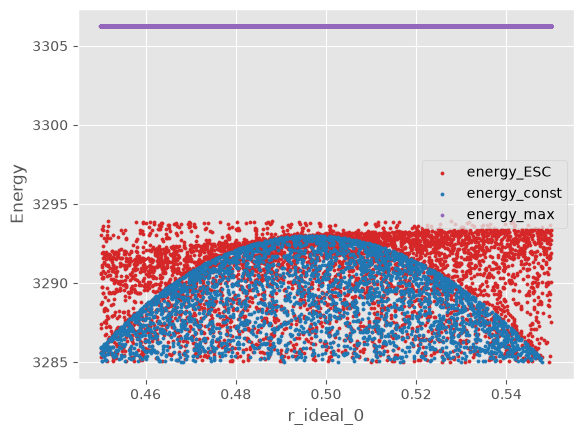

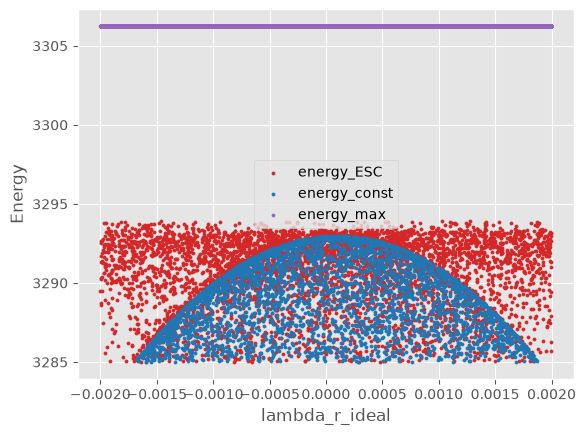

In [17]:
for i in parameter_columns:
    ax = df[df['energy_ESC'] > 3285].plot(kind = 'scatter', x = i, y = 'energy_ESC', color = 'tab:red', label = 'energy_ESC', s = 5)
    df[df['energy_const'] > 3285].plot(kind = 'scatter', x = i, y = 'energy_const', color = 'tab:blue', label = 'energy_const', s = 5, ax = ax)
    df[df['energy_max'] > 3285].plot(kind = 'scatter', x = i, y = 'energy_max', color = 'tab:purple', label = 'energy_max', s = 5, ax = ax)
    ax.set_ylabel('Energy')
    plt.show()

#### Analyse ESC

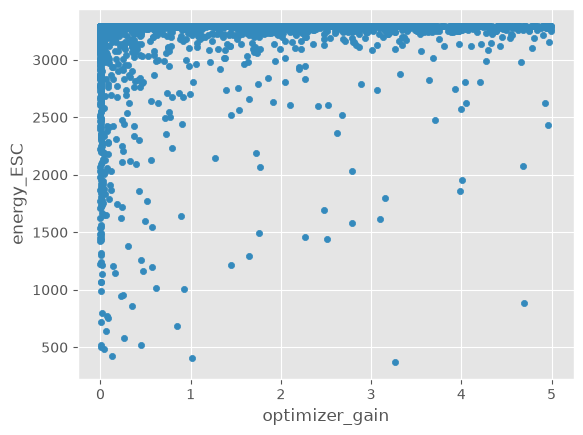

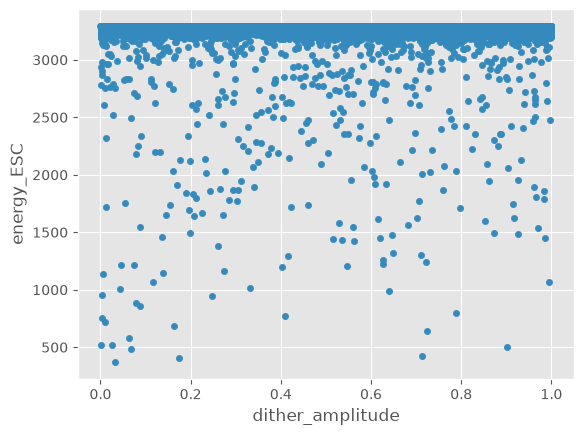

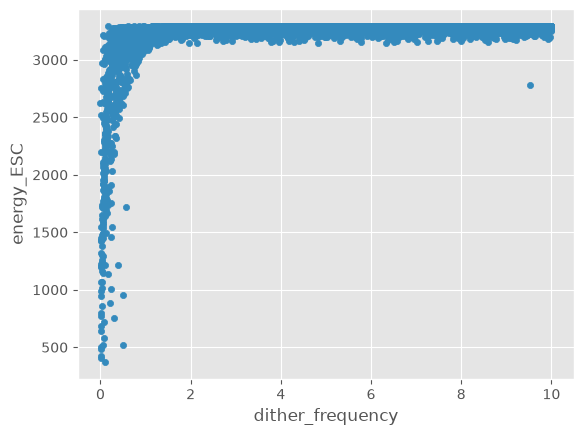

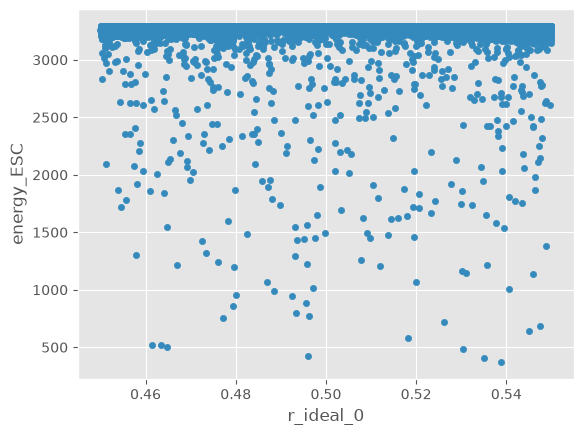

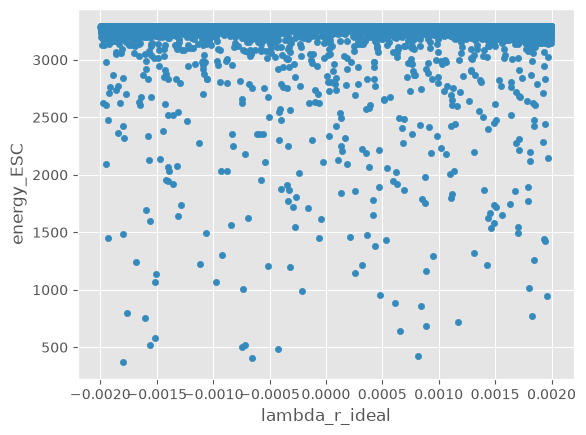

In [18]:
for i in parameter_columns:
    df.plot(kind = 'scatter',
            x = i,
            y = 'energy_ESC')
    plt.show()

## Cut dataset

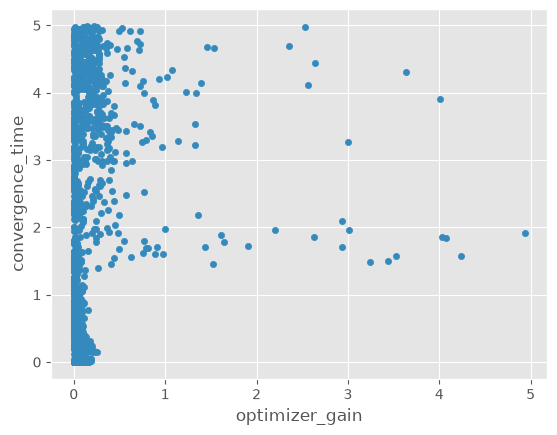

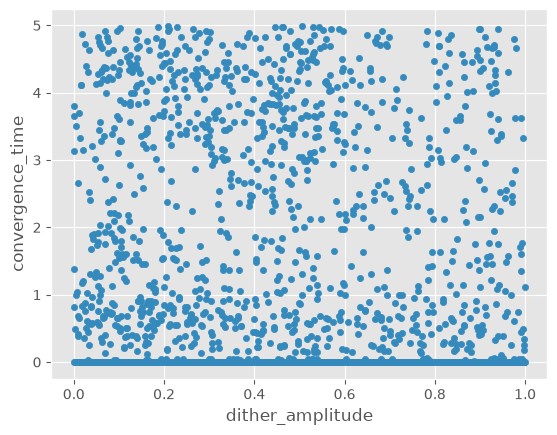

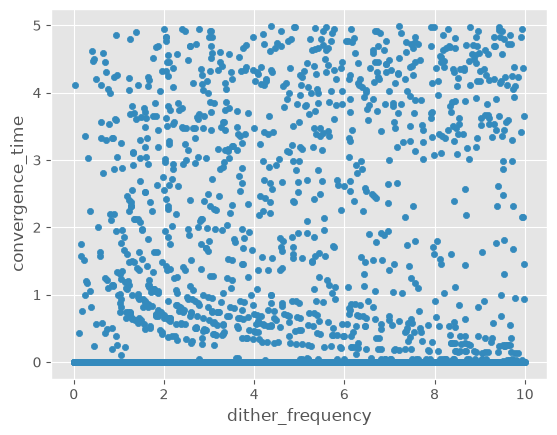

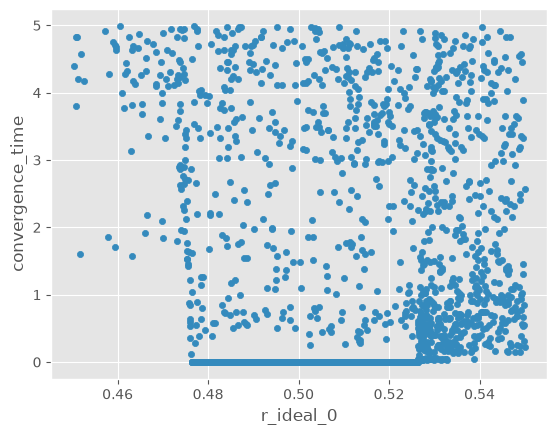

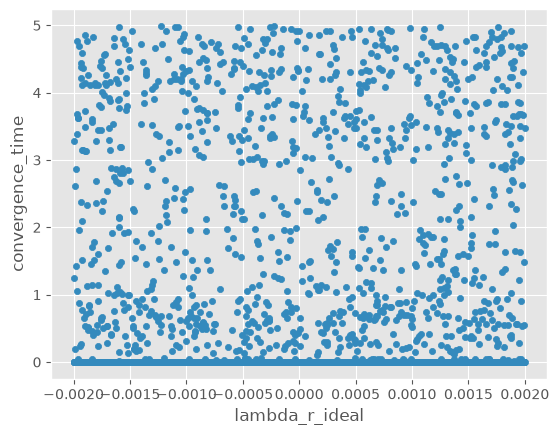

In [19]:
dfcut = df[df['convergence_time'] < 5]
for i in parameter_columns:
    dfcut.plot(kind = 'scatter',
            x = i,
            y = 'convergence_time')
    plt.show()


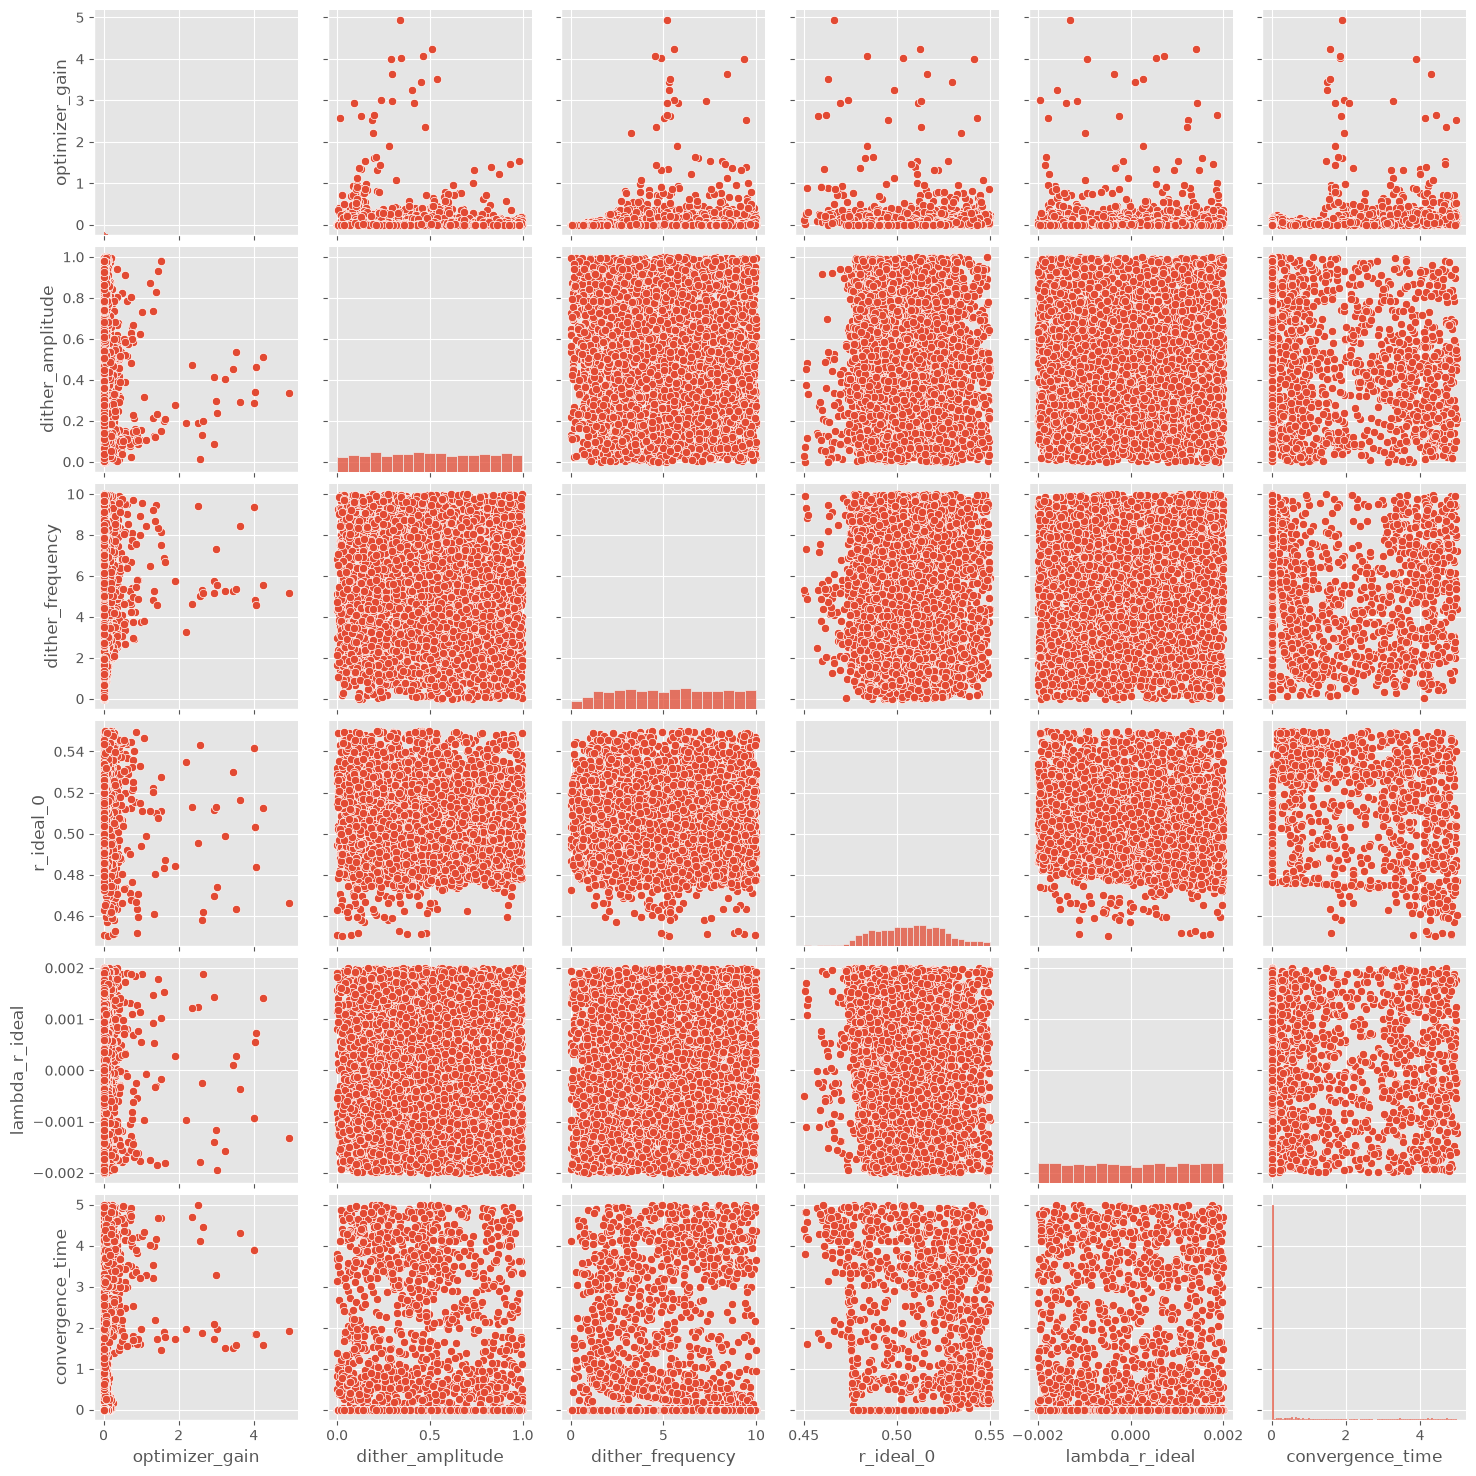

In [20]:
sns.pairplot(dfcut,
             vars = parameter_columns + ['convergence_time'])
plt.show()


<Axes: >

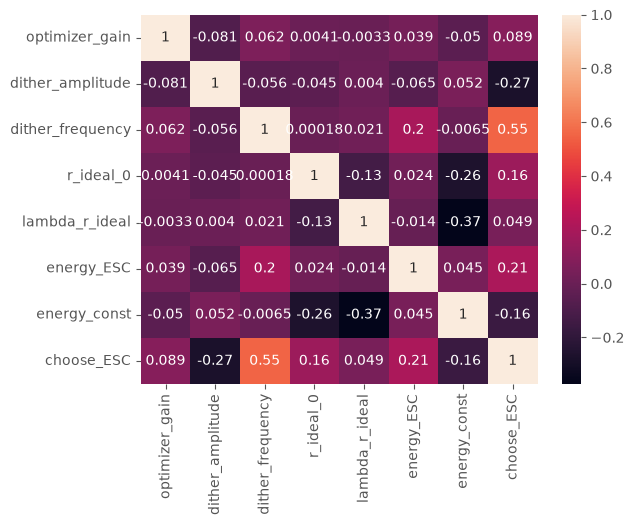

In [21]:
sns.heatmap(dfcut.drop(columns = ['converged', 'convergence_time', 'energy_max']).corr(), annot = True)


I think it would be useful to plot a 3d plot to visualize where the false predictions are.

# Visualization

In [22]:
import plotly.express as px

In [23]:
fig10k = px.scatter_3d(df,
                    x = 'optimizer_gain',
                    y = 'dither_amplitude',
                    z = 'dither_frequency',
                    color = 'convergence_time',
                    title = '3D scatter',
                    labels = {'optimizer_gain' : 'Optimizer gain',
                              'dither_amplitude' : 'Dither amplitude',
                              'dither_frequency' : 'Dither Frequency'})
fig10k.update_traces(marker=dict(size=3))
fig10k.show()

In [24]:
# Exporting the plot (put it comment as I would run the notebook all over every time I open)
# fig10k.write_html("3dscatter10k.html")

In [25]:
fig10k_E = px.scatter_3d(df,
                    x = 'optimizer_gain',
                    y = 'dither_amplitude',
                    z = 'dither_frequency',
                    color = 'energy_ESC',
                    color_continuous_scale = 'Blues',
                    title = '3D scatter: ESC energy',
                    labels = {'optimizer_gain' : 'Optimizer gain',
                              'dither_amplitude' : 'Dither amplitude',
                              'dither_frequency' : 'Dither Frequency',
                              'energy_ESC' : 'ESC energy'})
fig10k_E.update_traces(marker=dict(size=3))
fig10k_E.show()

# Modelling: Classification

In [26]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

torch.manual_seed(1)  #reproducible weights and batch shuffling

In [27]:
# Adding more features to the dataset
df['log10gain'] = np.log10(df['optimizer_gain'])
df['sinfre'] = np.sin(df['dither_frequency'])
df['product'] = df['optimizer_gain'] * df['dither_amplitude'] * df['sinfre']

In [28]:
# Create training sets

X = df[parameter_columns + ['log10gain', 'sinfre', 'product']]
y = df['choose_ESC']

# Get 60% of the dataset as the training set. Put the remaining 40% in temporary variables: x_ and y_.
X_train, X_, y_train, y_ = train_test_split(X, y, test_size=0.40, random_state=1)

# Split the 40% subset above into two: one half for cross validation and the other for the test set
X_cv, X_test, y_cv, y_test = train_test_split(X_, y_, test_size=0.50, random_state=1)

# Delete temporary variables
del X_, y_

In [29]:
# Convert to float32 tensors
Xtr = torch.tensor(X_train.values, dtype=torch.float32)
ytr = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
Xcv = torch.tensor(X_cv.values, dtype=torch.float32)
ycv = torch.tensor(y_cv.values, dtype=torch.float32).reshape(-1, 1)

# Mini-batches of 100, reshuffled every epoch
train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=100, shuffle=True)

In [30]:
# Defining models

n = Xtr.shape[1]  #number of input features

model1 = nn.Sequential(
    nn.Linear(n, 32), nn.ReLU(),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 1)
)

model2 = nn.Sequential(
    nn.Linear(n, 64), nn.ReLU(),
    nn.Linear(64, 32), nn.ReLU(),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 1)
)

In [31]:
def train(model, epochs=300, lr=0.01):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'loss': [], 'val_loss': []}

    for epoch in range(epochs):
        for xb, yb in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()

        with torch.no_grad():
            history['loss'].append(loss_fn(model(Xtr), ytr).item())
            history['val_loss'].append(loss_fn(model(Xcv), ycv).item())

    return history

def predict_logits(model, X):
    with torch.no_grad():
        return model(X)

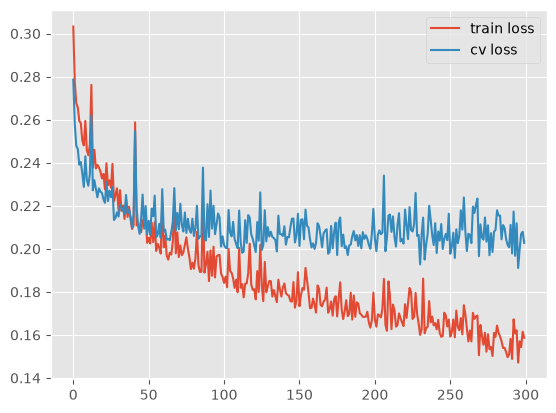

In [32]:
# Train with model 1

history1 = train(model1)
plt.plot(history1['loss'], label='train loss')
plt.plot(history1['val_loss'], label='cv loss')
plt.legend()
plt.show()

In [33]:
logits1 = predict_logits(model1, Xcv)
probs1 = torch.sigmoid(logits1).numpy() # convert logit to probability
y_pred1 = (probs1 > 0.5).astype(int).flatten() # threshold at 0.5, flatten to 1D
accuracy1 = accuracy_score(y_cv, y_pred1)
print(f"CV accuracy: {accuracy1:.3f}")

CV accuracy: 0.914


In [34]:
print(confusion_matrix(y_cv, y_pred1))
print(classification_report(y_cv, y_pred1))

[[ 411   84]
 [  88 1417]]
              precision    recall  f1-score   support

           0       0.82      0.83      0.83       495
           1       0.94      0.94      0.94      1505

    accuracy                           0.91      2000
   macro avg       0.88      0.89      0.88      2000
weighted avg       0.91      0.91      0.91      2000



In [35]:
train_logits1 = predict_logits(model1, Xtr)
train_probs1 = torch.sigmoid(train_logits1).numpy()
train_pred1 = (train_probs1 > 0.5).astype(int).flatten()
train_acc1 = accuracy_score(y_train, train_pred1)
print(f"Train accuracy: {train_acc1:.3f}")

Train accuracy: 0.931


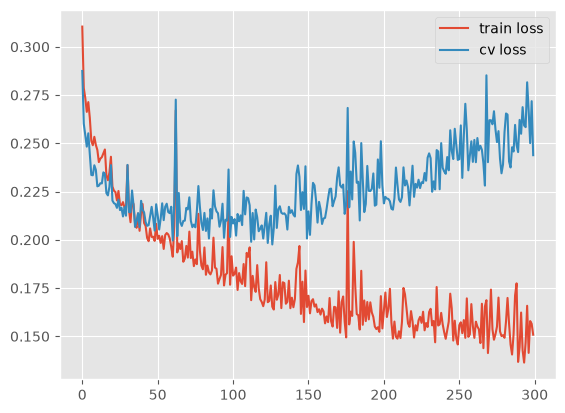

In [36]:
# Train with model 2

history2 = train(model2)
plt.plot(history2['loss'], label='train loss')
plt.plot(history2['val_loss'], label='cv loss')
plt.legend()
plt.show()

In [37]:
logits2 = predict_logits(model2, Xcv)
probs2 = torch.sigmoid(logits2).numpy() # convert logit to probability
y_pred2 = (probs2 > 0.5).astype(int).flatten() # threshold at 0.5, flatten to 1D
accuracy2 = accuracy_score(y_cv, y_pred2)
print(f"CV accuracy: {accuracy2:.3f}")

CV accuracy: 0.913


In [38]:
print(confusion_matrix(y_cv, y_pred2))
print(classification_report(y_cv, y_pred2))

[[ 397   98]
 [  76 1429]]
              precision    recall  f1-score   support

           0       0.84      0.80      0.82       495
           1       0.94      0.95      0.94      1505

    accuracy                           0.91      2000
   macro avg       0.89      0.88      0.88      2000
weighted avg       0.91      0.91      0.91      2000



In [39]:
train_logits2 = predict_logits(model2, Xtr)
train_probs2 = torch.sigmoid(train_logits2).numpy()
train_pred2 = (train_probs2 > 0.5).astype(int).flatten()
train_acc2 = accuracy_score(y_train, train_pred2)
print(f"Train accuracy: {train_acc2:.3f}")

Train accuracy: 0.929


I think there is still room for improvement, but we would have to analyse the wrong predictions first.

In [40]:
# Find where the false positives are
false_positive1 = (y_pred1 == 1) & (y_cv == 0)
X_cv1_df = pd.DataFrame(X_cv, columns=X_cv.columns)
print(X_cv1_df[false_positive1].describe())

false_positive2 = (y_pred2 == 1) & (y_cv == 0)
X_cv2_df = pd.DataFrame(X_cv, columns=X_cv.columns)
print(X_cv2_df[false_positive2].describe())

       optimizer_gain  dither_amplitude  dither_frequency  r_ideal_0  \
count       84.000000         84.000000         84.000000  84.000000   
mean         0.621921          0.491852          3.783931   0.491907   
std          1.150687          0.316568          2.279481   0.024406   
min          0.000025          0.002672          0.925936   0.450469   
25%          0.001213          0.258620          1.996232   0.469719   
50%          0.028942          0.488287          2.900644   0.492829   
75%          0.821489          0.787802          5.339525   0.506480   
max          4.950637          0.973491          9.765238   0.547640   

       lambda_r_ideal  log10gain     sinfre    product  
count       84.000000  84.000000  84.000000  84.000000  
mean         0.000168  -1.606866   0.256889   0.017493  
std          0.000954   1.569888   0.719591   0.578000  
min         -0.001972  -4.607365  -0.999239  -2.478153  
25%         -0.000331  -2.916121  -0.370560  -0.000252  
50%      

In [41]:
# Merge the false positives into 1 table

fp1 = X_cv1_df[false_positive1]
fp2 = X_cv2_df[false_positive2]

fp = pd.concat([fp1, fp2], ignore_index=True)
print(fp.describe())

       optimizer_gain  dither_amplitude  dither_frequency   r_ideal_0  \
count      182.000000        182.000000        182.000000  182.000000   
mean         0.541380          0.492176          3.629485    0.493069   
std          1.070187          0.313883          2.287509    0.024470   
min          0.000016          0.002672          0.329706    0.450469   
25%          0.001184          0.266324          1.956631    0.471801   
50%          0.025006          0.488287          2.837378    0.492854   
75%          0.560256          0.778739          5.033675    0.509111   
max          4.950637          0.991697          9.765238    0.547640   

       lambda_r_ideal   log10gain      sinfre     product  
count      182.000000  182.000000  182.000000  182.000000  
mean         0.000091   -1.724442    0.321165    0.005599  
std          0.000980    1.566960    0.692463    0.534806  
min         -0.001972   -4.796239   -0.999239   -2.478153  
25%         -0.000539   -2.926485   -0.266

In [42]:
# Drop duplicated rows of fp

fp = fp.loc[~fp.duplicated()].reset_index(drop = True)
print(fp.describe())

       optimizer_gain  dither_amplitude  dither_frequency   r_ideal_0  \
count      110.000000        110.000000        110.000000  110.000000   
mean         0.505490          0.493478          3.482643    0.494118   
std          1.055017          0.314314          2.232767    0.024403   
min          0.000016          0.002672          0.329706    0.450469   
25%          0.000666          0.243212          1.865451    0.475014   
50%          0.013714          0.495456          2.728206    0.493883   
75%          0.496392          0.756700          4.710113    0.509457   
max          4.950637          0.991697          9.765238    0.547640   

       lambda_r_ideal   log10gain      sinfre     product  
count      110.000000  110.000000  110.000000  110.000000  
mean         0.000038   -1.838065    0.344105    0.020481  
std          0.000974    1.577295    0.681619    0.505696  
min         -0.001972   -4.796239   -0.999239   -2.478153  
25%         -0.000616   -3.177030   -0.135

In [43]:
# Find where the false positives are
false_positive1 = (y_pred1 == 1) & (y_cv == 0)
X_cv1_df = pd.DataFrame(X_cv, columns=X_cv.columns)
print(X_cv1_df[false_positive1].describe())

false_positive2 = (y_pred2 == 1) & (y_cv == 0)
X_cv2_df = pd.DataFrame(X_cv, columns=X_cv.columns)
print(X_cv2_df[false_positive2].describe())

       optimizer_gain  dither_amplitude  dither_frequency  r_ideal_0  \
count       84.000000         84.000000         84.000000  84.000000   
mean         0.621921          0.491852          3.783931   0.491907   
std          1.150687          0.316568          2.279481   0.024406   
min          0.000025          0.002672          0.925936   0.450469   
25%          0.001213          0.258620          1.996232   0.469719   
50%          0.028942          0.488287          2.900644   0.492829   
75%          0.821489          0.787802          5.339525   0.506480   
max          4.950637          0.973491          9.765238   0.547640   

       lambda_r_ideal  log10gain     sinfre    product  
count       84.000000  84.000000  84.000000  84.000000  
mean         0.000168  -1.606866   0.256889   0.017493  
std          0.000954   1.569888   0.719591   0.578000  
min         -0.001972  -4.607365  -0.999239  -2.478153  
25%         -0.000331  -2.916121  -0.370560  -0.000252  
50%      

In [44]:
# Merge the false positives into 1 table

fp1 = X_cv1_df[false_positive1]
fp2 = X_cv2_df[false_positive2]

fp = pd.concat([fp1, fp2], ignore_index=True)
print(fp.describe())

       optimizer_gain  dither_amplitude  dither_frequency   r_ideal_0  \
count      182.000000        182.000000        182.000000  182.000000   
mean         0.541380          0.492176          3.629485    0.493069   
std          1.070187          0.313883          2.287509    0.024470   
min          0.000016          0.002672          0.329706    0.450469   
25%          0.001184          0.266324          1.956631    0.471801   
50%          0.025006          0.488287          2.837378    0.492854   
75%          0.560256          0.778739          5.033675    0.509111   
max          4.950637          0.991697          9.765238    0.547640   

       lambda_r_ideal   log10gain      sinfre     product  
count      182.000000  182.000000  182.000000  182.000000  
mean         0.000091   -1.724442    0.321165    0.005599  
std          0.000980    1.566960    0.692463    0.534806  
min         -0.001972   -4.796239   -0.999239   -2.478153  
25%         -0.000539   -2.926485   -0.266

In [45]:
# Drop duplicated rows of fp

fp = fp.loc[~fp.duplicated()].reset_index(drop = True)
print(fp.describe())

       optimizer_gain  dither_amplitude  dither_frequency   r_ideal_0  \
count      110.000000        110.000000        110.000000  110.000000   
mean         0.505490          0.493478          3.482643    0.494118   
std          1.055017          0.314314          2.232767    0.024403   
min          0.000016          0.002672          0.329706    0.450469   
25%          0.000666          0.243212          1.865451    0.475014   
50%          0.013714          0.495456          2.728206    0.493883   
75%          0.496392          0.756700          4.710113    0.509457   
max          4.950637          0.991697          9.765238    0.547640   

       lambda_r_ideal   log10gain      sinfre     product  
count      110.000000  110.000000  110.000000  110.000000  
mean         0.000038   -1.838065    0.344105    0.020481  
std          0.000974    1.577295    0.681619    0.505696  
min         -0.001972   -4.796239   -0.999239   -2.478153  
25%         -0.000616   -3.177030   -0.135

In [46]:
# Find where the false negatives are
false_negative1 = (y_pred1 == 0) & (y_cv == 1)
X_cv1_df = pd.DataFrame(X_cv, columns=X_cv.columns)
print(X_cv1_df[false_negative1].describe())

false_negative2 = (y_pred2 == 0) & (y_cv == 1)
X_cv2_df = pd.DataFrame(X_cv, columns=X_cv.columns)
print(X_cv2_df[false_negative2].describe())

       optimizer_gain  dither_amplitude  dither_frequency  r_ideal_0  \
count       88.000000         88.000000         88.000000  88.000000   
mean         0.327987          0.476085          3.060905   0.498661   
std          0.930098          0.328558          2.062548   0.029415   
min          0.000014          0.000508          0.441023   0.450005   
25%          0.000263          0.184710          1.379483   0.473599   
50%          0.002272          0.478153          2.575129   0.501958   
75%          0.076250          0.738023          3.931030   0.522240   
max          4.616517          0.994110          9.746769   0.549744   

       lambda_r_ideal  log10gain     sinfre    product  
count       88.000000  88.000000  88.000000  88.000000  
mean         0.000152  -2.371403   0.299518   0.061464  
std          0.001323   1.531934   0.710203   0.462126  
min         -0.001990  -4.840586  -0.999863  -1.891194  
25%         -0.001087  -3.580325  -0.346357  -0.000029  
50%      

In [47]:
# Merge the false negatives into 1 table

fn1 = X_cv1_df[false_negative1]
fn2 = X_cv2_df[false_negative2]

fn = pd.concat([fn1, fn2], ignore_index=True)
print(fn.describe())

       optimizer_gain  dither_amplitude  dither_frequency   r_ideal_0  \
count      164.000000        164.000000        164.000000  164.000000   
mean         0.327889          0.456030          3.100989    0.500839   
std          0.933923          0.326593          2.030083    0.030848   
min          0.000014          0.000508          0.441023    0.450005   
25%          0.000251          0.107850          1.431990    0.473599   
50%          0.001916          0.473490          2.975419    0.506228   
75%          0.068012          0.732061          3.946583    0.527025   
max          4.635183          0.994110          9.746769    0.549744   

       lambda_r_ideal   log10gain      sinfre     product  
count      164.000000  164.000000  164.000000  164.000000  
mean         0.000217   -2.408075    0.224709    0.090330  
std          0.001285    1.525945    0.707953    0.475866  
min         -0.001990   -4.848683   -0.999863   -1.891194  
25%         -0.000970   -3.601161   -0.429

In [48]:
# Drop duplicated rows of fn

fn = fn.loc[~fn.duplicated()].reset_index(drop = True)
print(fn.describe())

       optimizer_gain  dither_amplitude  dither_frequency   r_ideal_0  \
count      117.000000        117.000000        117.000000  117.000000   
mean         0.352010          0.486734          3.290490    0.502707   
std          0.963191          0.337418          2.117936    0.030059   
min          0.000014          0.000508          0.441023    0.450005   
25%          0.000267          0.122941          1.575645    0.477602   
50%          0.002034          0.491663          3.042174    0.506874   
75%          0.075385          0.783675          4.253743    0.528895   
max          4.635183          0.994110          9.746769    0.549744   

       lambda_r_ideal   log10gain      sinfre     product  
count      117.000000  117.000000  117.000000  117.000000  
mean         0.000202   -2.367511    0.205569    0.085579  
std          0.001246    1.562600    0.715728    0.479488  
min         -0.001990   -4.848683   -0.999863   -1.891194  
25%         -0.000876   -3.573380   -0.494

I realized that I did not pay enough attention to thhe dither amplitude. 
I will generate another dataset with wider range of dither amplitude (and dither frequency) to hopefully get a symmetric 3d plot.
I need to increase the range of all 3 parameters.